# 1. CV Calibration Results
- Calibration of held-out HC Z-scores across CV folds (inputs: `config.CV_DIR`, `config.ENGINE_DIR`).

In [1]:
%load_ext autoreload
%autoreload 2

import importlib
import os
import pickle
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.environ["NM_PIPELINE"] = "p0"
sys.path.insert(0, str(Path.cwd().parents[1]))
import MixedEffectsModeling.config as config
importlib.reload(config)
from viz_style import apply_style, FS_ANNOT_LG, FS_ANNOT_SM
apply_style()

CV = config.CV_DIR
ENG = config.ENGINE_DIR
FIG = CV / 'Figures'
FIG.mkdir(parents=True, exist_ok=True)

# Reference values a correctly-specified normative model must hit on held-out HC (a true null).
TARGET = {'mean_z': 0.0, 'std_z': 1.0, 'exceed': 0.05, 'med_z2': 0.4549}  # med_z2 = median of chi2(df=1)

NZ_BINS = [30, 40, 50, 60, 80, 100, 150, 200, 250, 300, 350, 400, 450, 500, 550, 592]
NZ_LABELS = [
    f'{NZ_BINS[i]+1}={NZ_BINS[i+1]}' for i in range(0, len(NZ_BINS)-1)
]

In [2]:
# 0. Load CV artifacts
fold = pd.read_csv(CV / 'fold_stats.csv')
pool_fold = pd.read_csv(CV / 'pool_fold_stats.csv')
cv = pd.read_csv(CV / 'cv_stats.csv')
train = pd.read_csv(ENG / 'training_summary.csv')

# per-gene fold stability: a gene is "stable" only if the individual GLMM converged in all 5 folds
stab = fold.groupby('gene')['ok'].sum().rename('n_fold_ok').reset_index()
cv = cv.merge(stab, on='gene', how='left')
cv['stable'] = cv['n_fold_ok'] == config.SPIKE_PARAMS['n_splits']
cv['nz_bin'] = pd.cut(cv['nz'], bins=NZ_BINS, labels=NZ_LABELS)
cv['route_stage'] = cv['route'] + '/' + cv['stage']

print(f"engine ok genes: {int(train['ok'].sum())} | cv_stats rows: {len(cv)} "
      f"(missing {int(train['ok'].sum()) - len(cv)}: all folds failed)")
print(f"model route: {int((cv.route == 'model').sum())} | pool route: {int((cv.route == 'pool').sum())}")
print(f"\npool-route fold fits (one shared GLMM per fold):\n{pool_fold.to_string(index=False)}")
display(cv.groupby('route_stage').agg(
    n=('gene', 'size'), nz_med=('nz', 'median'), mean_z=('mean_z', 'mean'), std_z=('std_z', 'mean'),
    exceed=('cv_naive_exceed', 'mean'), stable=('stable', 'mean')).round(4))

engine ok genes: 19917 | cv_stats rows: 19917 (missing 0: all folds failed)
model route: 17629 | pool route: 2288

pool-route fold fits (one shared GLMM per fold):
 fold   ok family  fail_reason
    0 True negbin          NaN
    1 True negbin          NaN
    2 True negbin          NaN
    3 True negbin          NaN
    4 True negbin          NaN


,n,nz_med,mean_z,std_z,exceed,stable
route_stage,,,,,,
model/nbi_full_eb,17588,506.0,0.0083,1.0265,0.0551,0.9852
model/nbi_intercept_eb,41,55.0,0.0076,1.0125,0.0493,0.1463
pool/pool,2288,13.0,-0.0042,0.9560,0.0409,0.0000


model-route fold success: 0.9956 (87756/88145)
genes converging in all 5 folds: 0.9832

train-stage routing (deployed engine):
route     stage           
excluded  nbi_intercept_eb      180
model     nbi_full_eb         17588
          nbi_intercept_eb       41
pool      pool                 2288

fold fail_reason:
fail_reason
not_converged_or_explosion_or_tau2_bound    389


,n_gene,fold_ok,all5_ok
nz_bin,,,
31=40,442,0.9371,0.7738
41=50,385,0.9605,0.8416
51=60,353,0.9768,0.9235
61=80,616,0.9808,0.9286
81=100,541,0.9937,0.9741
101=150,966,0.9969,0.9855
151=200,777,0.9961,0.9833
201=250,638,0.9953,0.9796
251=300,586,0.9973,0.9881


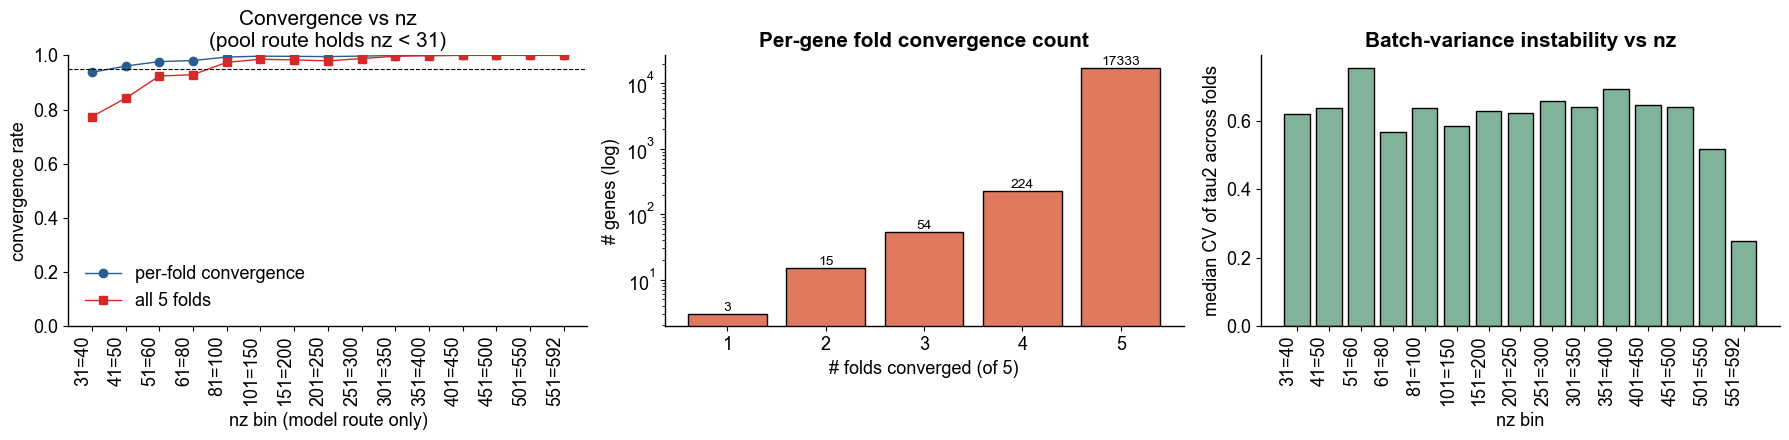

In [3]:
fold_nz = fold.merge(train[['gene', 'nz']], on='gene')
fold_nz['nz_bin'] = pd.cut(fold_nz['nz'], bins=NZ_BINS, labels=NZ_LABELS)
by_nz = fold_nz.groupby('nz_bin', observed=True).agg(n_gene=('gene', 'nunique'), fold_ok=('ok', 'mean'))
by_nz['all5_ok'] = cv[cv.route == 'model'].groupby('nz_bin', observed=True)['stable'].mean()

print(f"model-route fold success: {fold['ok'].mean():.4f} ({int(fold['ok'].sum())}/{len(fold)})")
print(f"genes converging in all 5 folds: {cv.loc[cv.route == 'model', 'stable'].mean():.4f}")
print(f"\ntrain-stage routing (deployed engine):\n"
      f"{train.groupby(['route', 'stage'], dropna=False).size().to_string()}")
print(f"\nfold fail_reason:\n{fold.loc[~fold['ok'], 'fail_reason'].fillna('(blank)').value_counts().to_string()}")
display(by_nz.round(4))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
x = np.arange(len(by_nz))
axes[0].plot(x, by_nz['fold_ok'], marker='o', color='#2b5c8f', label='per-fold convergence')
axes[0].plot(x, by_nz['all5_ok'], marker='s', color='#d62828', label='all 5 folds')
axes[0].axhline(0.95, color='black', linewidth=0.8, linestyle='--')
axes[0].set_xticks(x); axes[0].set_xticklabels(by_nz.index, rotation=90, ha='right')
axes[0].set_ylabel('convergence rate'); axes[0].set_xlabel('nz bin (model route only)')
axes[0].set_title(f'Convergence vs nz\n(pool route holds nz < {config.NZ_A_MAX})')
axes[0].set_ylim(0, 1)
axes[0].legend(frameon=False)

nfold = cv.loc[cv.route == 'model', 'n_fold_ok'].value_counts().sort_index()
axes[1].bar(nfold.index.astype(int), nfold.values, color='#e07a5f', edgecolor='black')
axes[1].set_yscale('log')
axes[1].set_xlabel('# folds converged (of 5)'); axes[1].set_ylabel('# genes (log)')
axes[1].set_title('Per-gene fold convergence count',fontweight='bold')
for i, v in zip(nfold.index.astype(int), nfold.values):
    axes[1].text(i, v, str(int(v)), ha='center', va='bottom') 

# tau2 is refit per fold; its spread across folds is a second, continuous stability read-out that
# does not depend on the binary convergence flag.
t2 = fold_nz[fold_nz['ok']].groupby('gene').agg(tau2_cv=('tau2', lambda v: v.std() / max(v.mean(), 1e-9)),
                                                nz=('nz', 'first'))
t2['nz_bin'] = pd.cut(t2['nz'], bins=NZ_BINS, labels=NZ_LABELS)
med = t2.groupby('nz_bin', observed=True)['tau2_cv'].median()
axes[2].bar(np.arange(len(med)), med.values, color='#81b29a', edgecolor='black')
axes[2].set_xticks(np.arange(len(med))); axes[2].set_xticklabels(med.index, rotation=90, ha='right')
axes[2].set_ylabel('median CV of tau2 across folds'); axes[2].set_xlabel('nz bin')
axes[2].set_title('Batch-variance instability vs nz',fontweight='bold')

plt.tight_layout(); plt.savefig(FIG / 'cv_convergence.png', dpi=150, bbox_inches='tight'); plt.show()

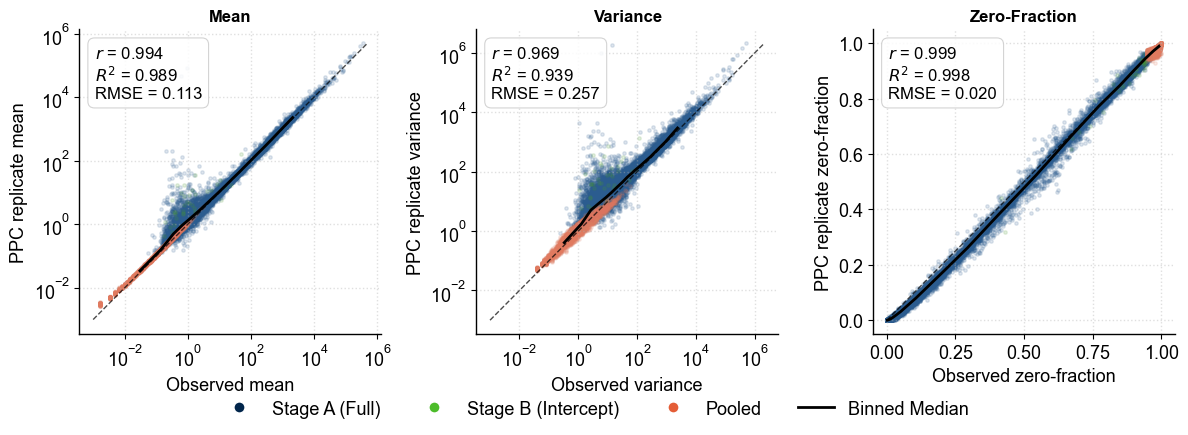

held-out calibration, CV-based PPC replicates (log10 scale for mean/var, linear for zero):
  Mean           (all)   : r=0.9944  R2=0.9887  RMSE=0.1133  n=19917
  Mean           (Stage A (Full)    ): r=0.9929  R2=0.9859  RMSE=0.1184  n=17588
  Mean           (Stage B (Intercept)): r=0.7322  R2=0.5362  RMSE=0.4651  n=41
  Mean           (Pooled            ): r=0.9988  R2=0.9976  RMSE=0.0080  n=2288
  Variance       (all)   : r=0.9691  R2=0.9391  RMSE=0.2569  n=19917
  Variance       (Stage A (Full)    ): r=0.9569  R2=0.9156  RMSE=0.2683  n=17588
  Variance       (Stage B (Intercept)): r=0.5488  R2=0.3011  RMSE=0.9113  n=41
  Variance       (Pooled            ): r=0.9651  R2=0.9314  RMSE=0.0790  n=2288
  Zero-Fraction  (all)   : r=0.9992  R2=0.9985  RMSE=0.0202  n=19917
  Zero-Fraction  (Stage A (Full)    ): r=0.9989  R2=0.9978  RMSE=0.0212  n=17588
  Zero-Fraction  (Stage B (Intercept)): r=0.9838  R2=0.9679  RMSE=0.0272  n=41
  Zero-Fraction  (Pooled            ): r=0.7878  R2=0.6206  RM

In [4]:
from MixedEffectsModeling.validation.ppc_simulate import simulate_marginal_nb
from matplotlib.lines import Line2D

PPC_N_REPS = 200
CAL_CACHE = CV / 'cv_calibration_moments.csv'

if CAL_CACHE.exists():
    cal = pd.read_csv(CAL_CACHE)
else:
    ppcd = pickle.load(open(CV / 'cv_ppc.pkl', 'rb'))
    rows = []
    for i, (g, d) in enumerate(ppcd.items()):
        y = np.asarray(d['y'], float)
        mu = np.asarray(d['mu'], float)
        alpha = np.asarray(d['alpha'], float)
        tau2 = np.asarray(d['tau2'], float)
        if y.size == 0 or not (np.isfinite(mu).all() and np.isfinite(alpha).all() and np.isfinite(tau2).all()):
            continue
        y_rep = simulate_marginal_nb(mu, alpha, tau2, PPC_N_REPS, seed=1000 + i)
        rows.append({
            'gene': g, 
            'obs_mean': y.mean(), 
            'pred_mean': y_rep.mean(1).mean(),
            'obs_var': y.std(), 
            'pred_var': y_rep.std(1).mean(),
            'obs_zero': (y == 0).mean(), 
            'pred_zero': (y_rep == 0).mean(1).mean()
        })
    cal = pd.DataFrame(rows)
    cal.to_csv(CAL_CACHE, index=False)

cal = cal.merge(cv[['gene', 'route', 'stage']], on='gene', how='left')

STAGE_MAP = {
    'nbi_full_eb': ('Stage A (Full)', '#2b5c8f'),
    'nbi_intercept_eb': ('Stage B (Intercept)', '#499831'),
    'pool': ('Pooled', '#e07a5f')
}

from MixedEffectsModeling.validation.ppc_simulate import binned_medians, calib_stats

panels = [
    ('obs_mean', 'pred_mean', 'Mean', True),
    ('obs_var', 'pred_var', 'Variance', True),
    ('obs_zero', 'pred_zero', 'Zero-Fraction', False)
]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, (oc, pc, title_str, logsc) in zip(axes, panels):
    for stage_key, (label_name, color) in STAGE_MAP.items():
        s = cal[cal.stage == stage_key]
        ax.scatter(s[oc], s[pc], s=6, alpha=0.15, color=color)
    
    bx, by = binned_medians(cal[oc], cal[pc])
    ax.plot(bx, by, '-', color='black', linewidth=2)
    
    if logsc:
        lo = max(min(cal[oc].min(), cal[pc].min()), 1e-3)
        hi = max(cal[oc].max(), cal[pc].max())
        ax.plot([lo, hi], [lo, hi], 'k--', linewidth=1, alpha=0.7)
        ax.set_xscale('log')
        ax.set_yscale('log')
    else:
        ax.plot([0, 1], [0, 1], 'k--', linewidth=1, alpha=0.7)
        
    cs = calib_stats(cal[oc], cal[pc], logsc)
    
    ax.set_title(title_str, fontsize=FS_ANNOT_LG, fontweight='bold')
    ax.set_xlabel(f'Observed {title_str.lower()}')
    ax.set_ylabel(f'PPC replicate {title_str.lower()}')
    
    stats_text = "$r$ = {pearson_r:.3f}\n$R^2$ = {r2:.3f}\nRMSE = {rmse:.3f}".format(**cs)
    bbox_props = dict(boxstyle='round,pad=0.4', facecolor='white', alpha=0.85, edgecolor='#cccccc', linewidth=0.8)
    ax.text(0.05, 0.95, stats_text, transform=ax.transAxes, fontsize=FS_ANNOT_LG,
            verticalalignment='top', horizontalalignment='left', bbox=bbox_props)
    
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(True, linestyle=':', alpha=0.4)

legend_handles = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor="#01254b", markersize=8, label='Stage A (Full)'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor="#4CBC2A", markersize=8, label='Stage B (Intercept)'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor="#e45d37", markersize=8, label='Pooled'),
    Line2D([0], [0], color='black', lw=2, label='Binned Median')
]

fig.legend(handles=legend_handles, loc='lower center', bbox_to_anchor=(0.5, -0.1), ncol=4, frameon=False)

plt.tight_layout()
plt.subplots_adjust(bottom=0.15)
plt.savefig(FIG / 'cv_ppc_replicates.png', dpi=300, bbox_inches='tight')
plt.show()

print('held-out calibration, CV-based PPC replicates (log10 scale for mean/var, linear for zero):')
for oc, pc, lab, logsc in panels:
    cs = calib_stats(cal[oc], cal[pc], logsc)
    print('  {:14s} (all)   : r={pearson_r:.4f}  R2={r2:.4f}  RMSE={rmse:.4f}  n={n}'.format(lab, **cs))
    for stage_key, (label_name, _) in STAGE_MAP.items():
        sub = cal[cal.stage == stage_key]
        cs = calib_stats(sub[oc], sub[pc], logsc)
        print('  {:14s} ({:18s}): r={pearson_r:.4f}  R2={r2:.4f}  RMSE={rmse:.4f}  n={n}'.format(lab, label_name, **cs))

In [5]:
from scipy.stats import kurtosis, norm, skew

from MixedEffectsModeling.core.calibration import bh_fdr_reject

SHASH_CAL_PATH = CV / 'cv_shash_calibration.csv'
Q_LEVELS = (0.01, 0.005)

def qtag(q):
    return f'q{int(round(q * 1000)):03d}'

if SHASH_CAL_PATH.exists():
    shn = pd.read_csv(SHASH_CAL_PATH)
else:
    zdict = pickle.load(open(CV / 'cv_zscores.pkl', 'rb'))
    zdict_corr = pickle.load(open(CV / 'cv_zscores_shash.pkl', 'rb'))
    rows = []
    for g, z in zdict.items():
        finite = np.isfinite(z)
        z = z[finite].astype(np.float64)
        if len(z) < 20 or g not in zdict_corr:
            continue
        row = {'gene': g, 'n_valid': len(z)}

        row['raw_mean'] = float(np.mean(z)); row['raw_std'] = float(np.std(z))
        row['raw_skew'] = float(skew(z)); row['raw_kurt'] = float(kurtosis(z))
        pv_raw = 2 * norm.sf(np.abs(z))
        for q in Q_LEVELS:
            row[f'raw_n_out_{qtag(q)}'] = int(bh_fdr_reject(pv_raw, q=q).sum())

        z_corr = zdict_corr[g][finite]
        row['corr_mean'] = float(np.mean(z_corr)); row['corr_std'] = float(np.std(z_corr))
        row['corr_skew'] = float(skew(z_corr)); row['corr_kurt'] = float(kurtosis(z_corr))
        pv_corr = 2 * norm.sf(np.abs(z_corr))
        for q in Q_LEVELS:
            row[f'corr_n_out_{qtag(q)}'] = int(bh_fdr_reject(pv_corr, q=q).sum())

        rows.append(row)
    shn = pd.DataFrame(rows)
    shn.to_csv(SHASH_CAL_PATH, index=False)

print(f'saved -> {SHASH_CAL_PATH}  ({len(shn)} genes)')

saved -> /project/cfRNA_NormativeModeling/MixedEffectsModeling/Notebook_p0/CV_Results_mixed/cv_shash_calibration.csv  (19917 genes)


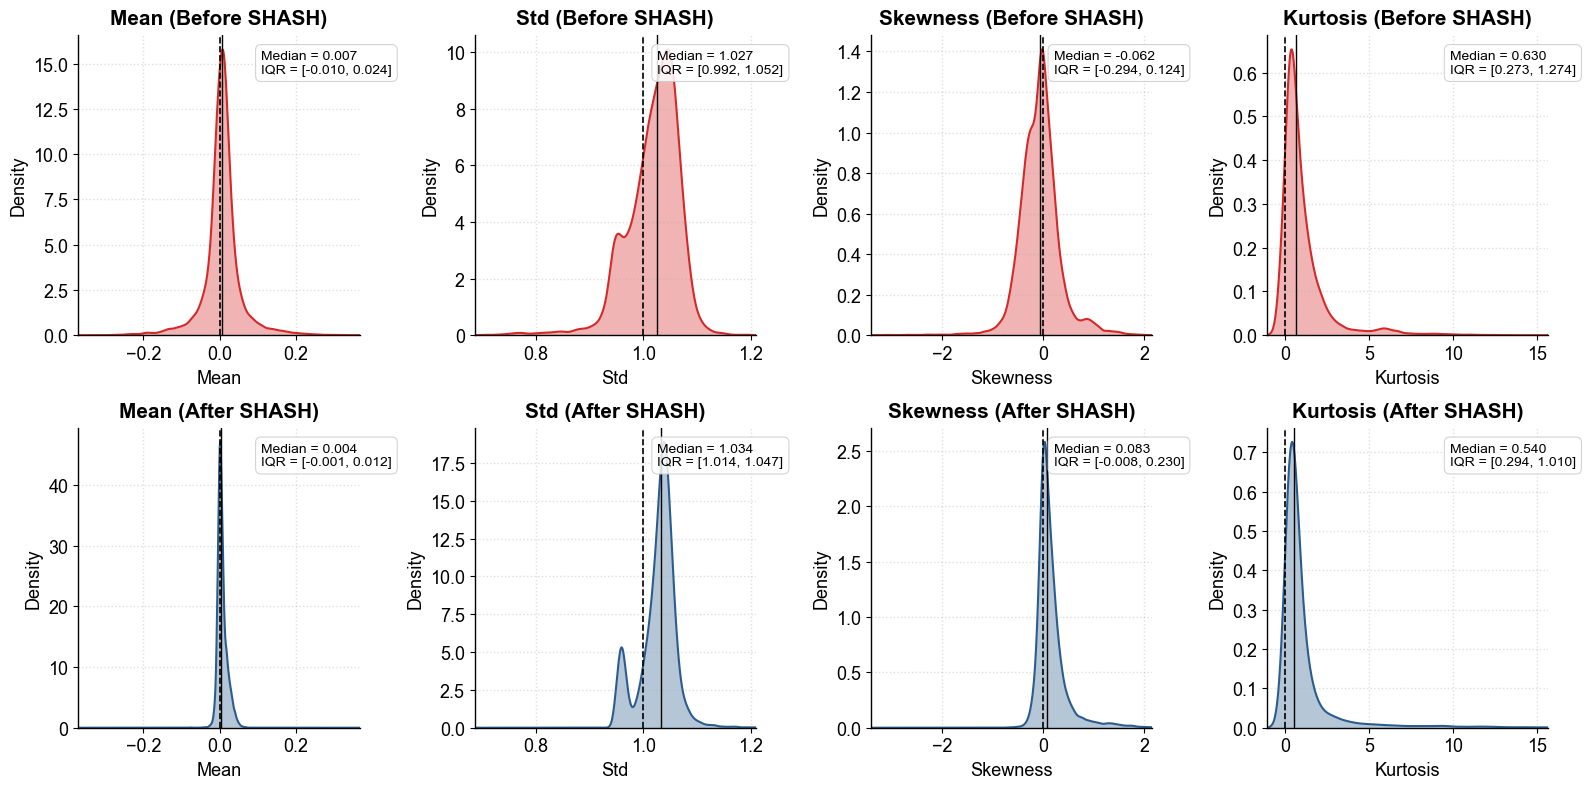

SHASH calibration, held-out CV (production, per-fold train-fit) (median [IQR]):
  Mean               ideal=+0.0   before=+0.0069 [-0.0101, +0.0238]   after=+0.0040 [-0.0012, +0.0125]
  Std                ideal=+1.0   before=+1.0265 [+0.9923, +1.0517]   after=+1.0340 [+1.0144, +1.0471]
  Skewness           ideal=+0.0   before=-0.0622 [-0.2942, +0.1237]   after=+0.0828 [-0.0084, +0.2302]
  Kurtosis           ideal=+0.0   before=+0.6298 [+0.2728, +1.2740]   after=+0.5404 [+0.2941, +1.0101]


In [6]:
from scipy.stats import gaussian_kde

cv2 = cv.merge(shn[['gene', 'corr_mean', 'corr_std', 'corr_skew', 'corr_kurt']], on='gene', how='left')

metrics = [
    ('Mean', 'mean_z', 'corr_mean', 0.0),
    ('Std', 'std_z', 'corr_std', 1.0),
    ('Skewness', 'cv_raw_skew', 'corr_skew', 0.0),
    ('Kurtosis', 'cv_raw_kurtosis', 'corr_kurt', 0.0)
]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for col, (lab, raw_c, corr_c, ideal) in enumerate(metrics):
    xlim = cv2[raw_c].dropna().quantile([0, 1]).values  # before-SHASH range, shared with after-SHASH panel
    rows_info = [
        (raw_c, f'{lab} (Before SHASH)', '#d62828'),
        (corr_c, f'{lab} (After SHASH)', '#2b5c8f')
    ]
    
    for row, (c, title, color) in enumerate(rows_info):
        ax = axes[row, col]
        v = cv2[c].dropna()
        
        grid = np.linspace(*xlim, 512)
        dens = gaussian_kde(v)(grid)
        ax.fill_between(grid, dens, color=color, alpha=0.35, lw=0)
        ax.plot(grid, dens, color=color, linewidth=1.5)
        ax.set_ylim(bottom=0)
        ax.axvline(ideal, color='black', linewidth=1.2, linestyle='--')
        ax.axvline(v.median(), color='black', linewidth=1.0)
        ax.set_xlim(xlim)
        
        ax.set_title(title, fontweight='bold', pad=8)
        ax.set_xlabel(lab)
        ax.set_ylabel('Density')
        
        med = v.median()
        q25 = v.quantile(0.25)
        q75 = v.quantile(0.75)
        stats_text = f"Median = {med:.3f}\nIQR = [{q25:.3f}, {q75:.3f}]"
        bbox_props = dict(boxstyle='round,pad=0.4', facecolor='white', alpha=0.85, edgecolor='#cccccc', linewidth=0.8)
        
        ax.text(0.65, 0.95, stats_text, transform=ax.transAxes,
                verticalalignment='top', horizontalalignment='left', bbox=bbox_props)
        
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.grid(True, linestyle=':', alpha=0.4)

plt.tight_layout()
plt.savefig(FIG / 'cv_shash_before_after.png', dpi=300, bbox_inches='tight')
plt.show()

print('SHASH calibration, held-out CV (production, per-fold train-fit) (median [IQR]):')
for lab, raw_c, corr_c, ideal in metrics:
    r, c = cv2[raw_c].dropna(), cv2[corr_c].dropna()
    print(f'  {lab:18s} ideal={ideal:+.1f}   before={r.median():+.4f} [{r.quantile(.25):+.4f}, {r.quantile(.75):+.4f}]'
          f'   after={c.median():+.4f} [{c.quantile(.25):+.4f}, {c.quantile(.75):+.4f}]')

genes with >=1 BH outlier -- raw vs SHASH-corrected (production, per-fold train-fit):
  q=0.010: genes flagged raw=7969 (0.4001)  corrected=8327 (0.4181)  | total outlier samples raw=13290  corrected=13113
  q=0.005: genes flagged raw=6778 (0.3403)  corrected=7134 (0.3582)  | total outlier samples raw=10402  corrected=10369


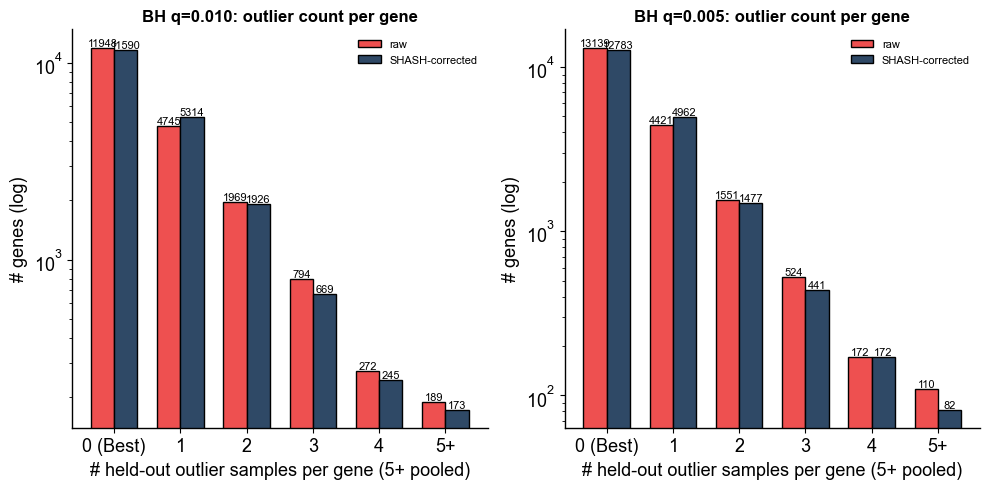

In [7]:
CAT_LABELS = ['0 (Best)', '1', '2', '3', '4', '5+']

def categorize(s):
    return pd.cut(s.clip(upper=5), bins=[-0.5, 0.5, 1.5, 2.5, 3.5, 4.5, 5.5], labels=CAT_LABELS)

print('genes with >=1 BH outlier -- raw vs SHASH-corrected (production, per-fold train-fit):')
for q in Q_LEVELS:
    tag = qtag(q)
    n_raw = (shn[f'raw_n_out_{tag}'] > 0).sum()
    n_corr = (shn[f'corr_n_out_{tag}'] > 0).sum()
    print(f'  q={q:.3f}: genes flagged raw={n_raw} ({n_raw/len(shn):.4f})  '
         f'corrected={n_corr} ({n_corr/len(shn):.4f})'
         f'  | total outlier samples raw={shn[f"raw_n_out_{tag}"].sum()}'
         f'  corrected={shn[f"corr_n_out_{tag}"].sum()}')

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
x = np.arange(len(CAT_LABELS)); w = 0.35
for ax, q in zip(axes, Q_LEVELS):
    tag = qtag(q)
    n_raw = categorize(shn[f'raw_n_out_{tag}']).value_counts().reindex(CAT_LABELS).values
    n_corr = categorize(shn[f'corr_n_out_{tag}']).value_counts().reindex(CAT_LABELS).values
    bars = [ax.bar(x + off, vals, w, color=c, edgecolor='black', label=lab)
           for off, vals, c, lab in [(-w / 2, n_raw, '#ee5050', 'raw'),
                                     (w / 2, n_corr, '#2f4966', 'SHASH-corrected')]]
    ax.set_yscale('log')
    for group in bars:
        for bar in group:
            h = bar.get_height()
            if h > 0:
                ax.text(bar.get_x() + bar.get_width() / 2, h, f'{int(h)}', ha='center', va='bottom', fontsize=FS_ANNOT_SM)
    ax.set_xticks(x); ax.set_xticklabels(CAT_LABELS)
    ax.set_xlabel('# held-out outlier samples per gene (5+ pooled)'); ax.set_ylabel('# genes (log)')
    ax.set_title(f'BH q={q:.3f}: outlier count per gene', fontsize=FS_ANNOT_LG, fontweight='bold')
    ax.legend(frameon=False, fontsize=FS_ANNOT_SM)
plt.tight_layout(); plt.savefig(FIG / 'cv_bh_outlier_raw_vs_corrected.png', dpi=150, bbox_inches='tight'); plt.show()

/tmp/ipykernel_401193/2423952851.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=bins_present, patch_artist=True, showfliers=False,
/tmp/ipykernel_401193/2423952851.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=bins_present, patch_artist=True, showfliers=False,
/tmp/ipykernel_401193/2423952851.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=bins_present, patch_artist=True, showfliers=False,


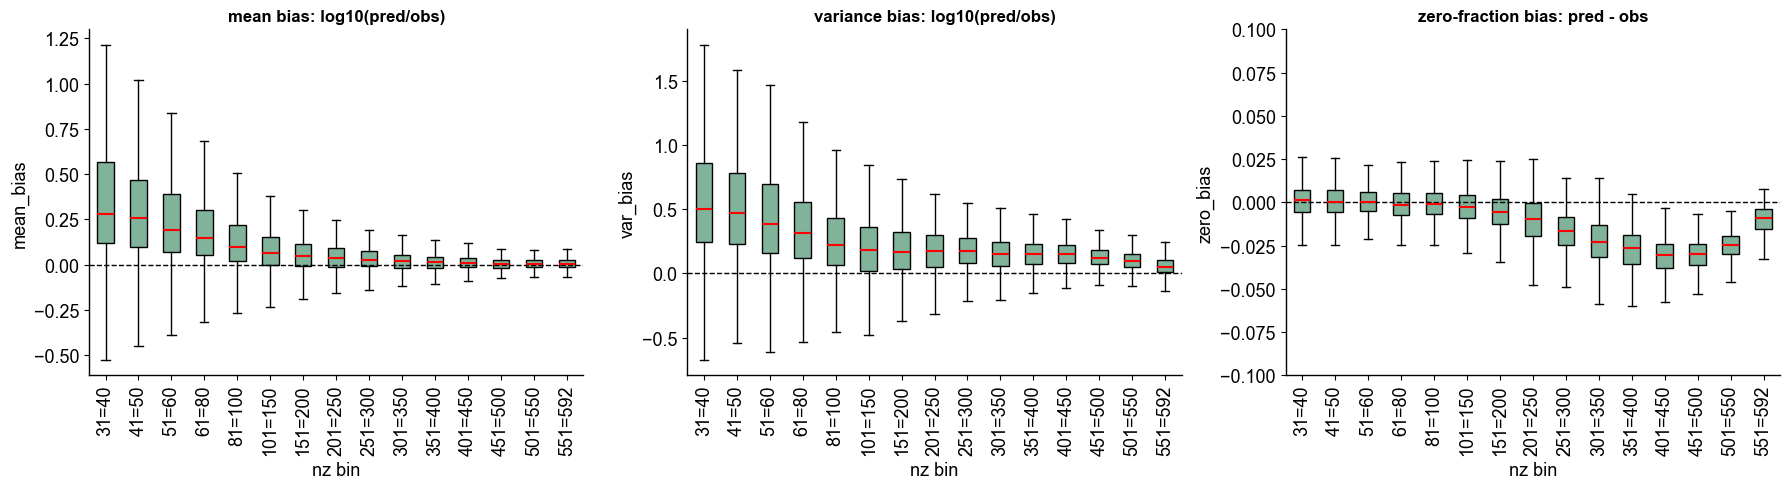

excluded (pool route, below first nz bin): 2288


,mean_bias,var_bias,zero_bias
nz_bin,,,
31=40,0.2782,0.5050,0.0015
41=50,0.2588,0.4737,0.0003
51=60,0.1902,0.3828,0.0001
61=80,0.1452,0.3121,-0.0017
81=100,0.0958,0.2214,-0.0010
101=150,0.0651,0.1812,-0.0028
151=200,0.0483,0.1674,-0.0056
201=250,0.0372,0.1764,-0.0099
251=300,0.0284,0.1737,-0.0165


In [8]:
bias = pd.read_csv(CV / 'cv_calibration_moments.csv').merge(cv[['gene', 'nz', 'nz_bin']], on='gene', how='left')
bias['mean_bias'] = np.log10(np.maximum(bias.pred_mean, 1e-8) / np.maximum(bias.obs_mean, 1e-8))
bias['var_bias'] = np.log10(np.maximum(bias.pred_var, 1e-8) / np.maximum(bias.obs_var, 1e-8))
bias['zero_bias'] = bias.pred_zero - bias.obs_zero

bins_present = [b for b in NZ_LABELS if bias.nz_bin.eq(b).any()]
panels = [('mean_bias', 'mean bias: log10(pred/obs)'),
         ('var_bias', 'variance bias: log10(pred/obs)'),
         ('zero_bias', 'zero-fraction bias: pred - obs')]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (col, title) in zip(axes, panels):
    data = [bias.loc[bias.nz_bin == b, col].dropna().values for b in bins_present]
    ax.boxplot(data, labels=bins_present, patch_artist=True, showfliers=False,
              boxprops=dict(facecolor='#81b29a', color='black'),
              medianprops=dict(color='red', linewidth=1.5))
    ax.axhline(0, color='black', linewidth=1, linestyle='--')
    ax.set_title(title, fontsize=FS_ANNOT_LG, fontweight='bold')
    ax.set_xlabel('nz bin'); ax.set_ylabel(col)
    ax.tick_params(axis='x', rotation=90)
    if col == 'zero_bias':
        ax.set_ylim(-0.1, 0.1)
plt.tight_layout(); plt.savefig(FIG / 'cv_ppc_bias_vs_nz.png', dpi=150, bbox_inches='tight'); plt.show()

print(f'excluded (pool route, below first nz bin): {bias.nz_bin.isna().sum()}')
display(bias.groupby('nz_bin', observed=True)[['mean_bias', 'var_bias', 'zero_bias']].median().round(4))